# Tugas UTS: Linear Regression & Logistic Regression
**Mata Kuliah:** Machine Learning

Notebook ini mengerjakan Simple Regression (`Ads_Data.csv`) dan Simple Classification (`Email_Data.csv`).

**Ketentuan:** implementasi model dan metrik utama dibuat manual menggunakan NumPy. Scikit-learn hanya digunakan pada bagian bonus.

**RANDOM_STATE:** 72 (dua digit terakhir NIM).


## Persiapan dan import library
Pastikan `Ads_Data.csv` dan `Email_Data.csv` berada satu folder dengan notebook ini.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RANDOM_STATE = 72
np.random.seed(RANDOM_STATE)
pd.set_option("display.max_columns", None)
plt.style.use("default")

ADS_PATH = Path("Ads_Data.csv")
EMAIL_PATH = Path("Email_Data.csv")

if not ADS_PATH.exists():
    raise FileNotFoundError(f"File tidak ditemukan: {ADS_PATH.resolve()}")
if not EMAIL_PATH.exists():
    raise FileNotFoundError(f"File tidak ditemukan: {EMAIL_PATH.resolve()}")

ads_df = pd.read_csv(ADS_PATH)
email_df = pd.read_csv(EMAIL_PATH)

print("Ads_Data.csv:", ads_df.shape)
display(ads_df.head())
print("Email_Data.csv:", email_df.shape)
display(email_df.head())


Ads_Data.csv: (40, 2)


,BiayaIklan,Penjualan
0,0.8,34.3
1,0.9,38.8
2,1.0,33.2
3,1.3,36.0
4,1.7,51.3


Email_Data.csv: (60, 3)


,JumlahLink,KataPromo,Spam
0,0,0,0
1,2,4,0
2,6,7,1
3,10,8,1
4,8,7,1


## Pemeriksaan data
Kolom yang diharapkan:
- Ads: `BiayaIklan`, `Penjualan`
- Email: `JumlahLink`, `KataPromo`, `Spam`


In [2]:
print("Kolom Ads:", ads_df.columns.tolist())
print("Kolom Email:", email_df.columns.tolist())
print("Tipe Ads:")
display(ads_df.dtypes.rename("dtype").to_frame())
print("Tipe Email:")
display(email_df.dtypes.rename("dtype").to_frame())
print("Missing Ads:")
display(ads_df.isna().sum().rename("jumlah").to_frame())
print("Missing Email:")
display(email_df.isna().sum().rename("jumlah").to_frame())
print("Duplikasi Ads:", int(ads_df.duplicated().sum()))
print("Duplikasi Email:", int(email_df.duplicated().sum()))
print("\nInfo Ads:")
display(ads_df.describe(include="all"))
print("\nInfo Email:")
display(email_df.describe(include="all"))

required_ads = {"BiayaIklan", "Penjualan"}
required_email = {"JumlahLink", "KataPromo", "Spam"}
if not required_ads.issubset(ads_df.columns):
    raise ValueError(f"Kolom Ads harus mencakup {required_ads}; ditemukan {set(ads_df.columns)}")
if not required_email.issubset(email_df.columns):
    raise ValueError(f"Kolom Email harus mencakup {required_email}; ditemukan {set(email_df.columns)}")
if ads_df[list(required_ads)].isna().any().any() or email_df[list(required_email)].isna().any().any():
    raise ValueError("Dataset mengandung nilai kosong pada kolom yang digunakan; bersihkan data terlebih dahulu.")
try:
    ads_df = ads_df.astype({"BiayaIklan": float, "Penjualan": float})
    email_df = email_df.astype({"JumlahLink": float, "KataPromo": float, "Spam": float})
except (TypeError, ValueError) as exc:
    raise ValueError("Kolom fitur dan target harus berisi nilai numerik.") from exc


Kolom Ads: ['BiayaIklan', 'Penjualan']
Kolom Email: ['JumlahLink', 'KataPromo', 'Spam']
Tipe Ads:


,dtype
BiayaIklan,float64
Penjualan,float64


Tipe Email:


,dtype
JumlahLink,int64
KataPromo,int64
Spam,int64


Missing Ads:


...

,jumlah
JumlahLink,0
KataPromo,0
Spam,0


Duplikasi Ads: 0
Duplikasi Email: 6

Info Ads:


,BiayaIklan,Penjualan
count,40.000000,40.000000
mean,5.055000,74.272500
std,2.718215,25.507867
min,0.800000,33.200000
25%,2.700000,52.525000
50%,4.950000,71.450000
75%,7.000000,93.550000
max,9.900000,121.100000



Info Email:


,JumlahLink,KataPromo,Spam
count,60.000000,60.000000,60.000000
mean,4.750000,5.983333,0.416667
std,3.078768,3.407328,0.497167
min,0.000000,0.000000,0.000000
25%,2.000000,3.000000,0.000000
50%,4.000000,6.000000,0.000000
75%,7.250000,9.000000,1.000000
max,10.000000,12.000000,1.000000


# A. Simple Linear Regression

## A1. Memahami dan memvisualisasikan data


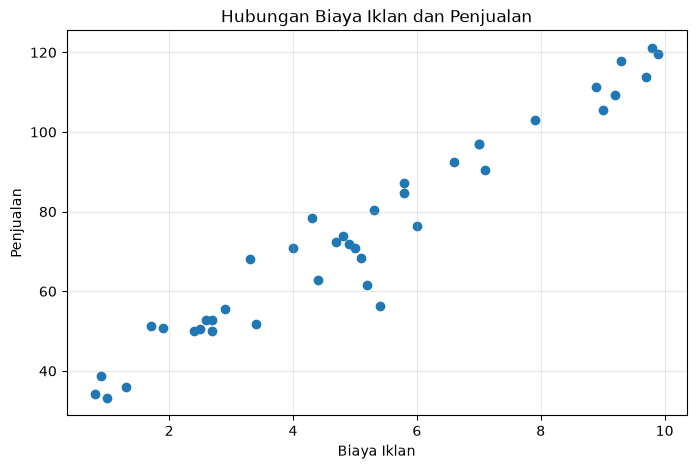

Jumlah data: 40
Korelasi: 0.9711888450360172


In [3]:
X_ads_all = ads_df["BiayaIklan"].to_numpy(dtype=float)
y_ads_all = ads_df["Penjualan"].to_numpy(dtype=float)

plt.figure(figsize=(8, 5))
plt.scatter(X_ads_all, y_ads_all)
plt.xlabel("Biaya Iklan")
plt.ylabel("Penjualan")
plt.title("Hubungan Biaya Iklan dan Penjualan")
plt.grid(True, alpha=0.3)
plt.show()

print("Jumlah data:", len(ads_df))
print("Korelasi:", np.corrcoef(X_ads_all, y_ads_all)[0, 1])


## A2. Membagi data train dan test
Pembagian manual menggunakan `RANDOM_STATE=72`, dengan 80% data training dan 20% data testing.


In [4]:
def train_test_split_manual(X, y, test_size=0.2, random_state=72, stratify=False, return_indices=False):
    X = np.asarray(X)
    y = np.asarray(y)
    if len(X) != len(y):
        raise ValueError("X dan y harus memiliki jumlah baris yang sama")
    if not 0 < test_size < 1:
        raise ValueError("test_size harus berada di antara 0 dan 1")
    rng = np.random.default_rng(random_state)
    if stratify:
        test_parts, train_parts = [], []
        for label in np.unique(y):
            class_indices = rng.permutation(np.flatnonzero(y == label))
            class_test_count = int(np.ceil(len(class_indices) * test_size))
            if class_test_count == 0 or class_test_count == len(class_indices):
                raise ValueError(f"Jumlah sampel kelas {label} tidak cukup untuk split stratified")
            test_parts.append(class_indices[:class_test_count])
            train_parts.append(class_indices[class_test_count:])
        test_idx = rng.permutation(np.concatenate(test_parts))
        train_idx = rng.permutation(np.concatenate(train_parts))
    else:
        indices = rng.permutation(len(X))
        test_count = int(np.ceil(len(X) * test_size))
        test_idx = indices[:test_count]
        train_idx = indices[test_count:]
    split = (X[train_idx], X[test_idx], y[train_idx], y[test_idx])
    if return_indices:
        return (*split, train_idx, test_idx)
    return split

X_train_ads, X_test_ads, y_train_ads, y_test_ads, train_idx_ads, test_idx_ads = train_test_split_manual(
    X_ads_all.reshape(-1, 1), y_ads_all, test_size=0.2, random_state=RANDOM_STATE, return_indices=True
)
assert not np.intersect1d(train_idx_ads, test_idx_ads).size
assert np.array_equal(X_train_ads[:, 0], X_ads_all[train_idx_ads])
assert np.array_equal(X_test_ads[:, 0], X_ads_all[test_idx_ads])
print("Data train:", len(X_train_ads))
print("Data test:", len(X_test_ads))


Data train: 32
Data test: 8


## A3. Model Linear Regression dengan persamaan normal
Model: ŷ = b₀ + b₁x. Parameter dihitung menggunakan least squares.


In [5]:
def fit_linear_regression_normal(X, y):
    X = np.asarray(X, dtype=float).reshape(-1, 1)
    y = np.asarray(y, dtype=float).reshape(-1, 1)
    X_bias = np.column_stack([np.ones(len(X)), X])
    theta = np.linalg.pinv(X_bias.T @ X_bias) @ X_bias.T @ y
    return theta.ravel()

def predict_linear(X, theta):
    X = np.asarray(X, dtype=float).reshape(-1, 1)
    X_bias = np.column_stack([np.ones(len(X)), X])
    return X_bias @ np.asarray(theta)

theta_normal = fit_linear_regression_normal(X_train_ads, y_train_ads)
pred_train_normal = predict_linear(X_train_ads, theta_normal)
pred_test_normal = predict_linear(X_test_ads, theta_normal)
print(f"Intercept (b0): {theta_normal[0]:.6f}")
print(f"Koefisien (b1): {theta_normal[1]:.6f}")


Intercept (b0): 27.709065
Koefisien (b1): 9.259671


## A4. Evaluasi model
Metrik dihitung manual: MAE, MSE, RMSE, dan R².


In [6]:
def mae_manual(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    return float(np.mean(np.abs(y_true - y_pred)))

def mse_manual(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    return float(np.mean((y_true - y_pred) ** 2))

def rmse_manual(y_true, y_pred):
    return float(np.sqrt(mse_manual(y_true, y_pred)))

def r2_manual(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    return float(1 - ss_res / ss_tot) if ss_tot != 0 else float("nan")

linear_results = pd.DataFrame({
    "Metrik": ["MAE", "MSE", "RMSE", "R2"],
    "Train": [
        mae_manual(y_train_ads, pred_train_normal),
        mse_manual(y_train_ads, pred_train_normal),
        rmse_manual(y_train_ads, pred_train_normal),
        r2_manual(y_train_ads, pred_train_normal),
    ],
    "Test": [
        mae_manual(y_test_ads, pred_test_normal),
        mse_manual(y_test_ads, pred_test_normal),
        rmse_manual(y_test_ads, pred_test_normal),
        r2_manual(y_test_ads, pred_test_normal),
    ],
})
display(linear_results)


,Metrik,Train,Test
0,MAE,4.045356,5.979788
1,MSE,25.932277,77.477408
2,RMSE,5.092374,8.802125
3,R2,0.960730,0.282292


## A5. Gradient Descent dengan beberapa learning rate
Gradient descent dijalankan selama 5000 iterasi dengan learning rate 0.001, 0.02, dan 0.1. Fitur distandardisasi agar optimisasi lebih stabil; prediksi tetap dikonversi ke satuan target asli.


,Learning rate,MSE train,MSE test,Loss akhir
0,0.001,25.932290,77.464858,25.932290
1,0.020,25.932277,77.477408,25.932277
2,0.100,25.932277,77.477408,25.932277


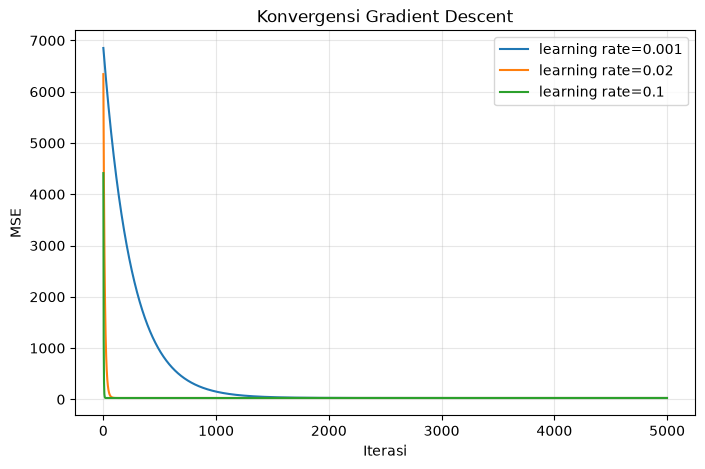

In [7]:
def fit_linear_gradient_descent(X, y, learning_rate=0.001, iterations=5000):
    X = np.asarray(X, dtype=float).reshape(-1, 1)
    y = np.asarray(y, dtype=float).reshape(-1)
    mean_x = X.mean(axis=0)
    std_x = X.std(axis=0)
    std_x[std_x == 0] = 1
    X_scaled = (X - mean_x) / std_x
    X_bias = np.column_stack([np.ones(len(X_scaled)), X_scaled])
    theta = np.zeros(X_bias.shape[1], dtype=float)
    losses = []
    for _ in range(iterations):
        pred = X_bias @ theta
        error = pred - y
        gradient = (2 / len(y)) * (X_bias.T @ error)
        theta -= learning_rate * gradient
        losses.append(np.mean((X_bias @ theta - y) ** 2))
    return theta, mean_x, std_x, np.asarray(losses)

def predict_linear_gd(X, fitted):
    theta, mean_x, std_x, _ = fitted
    X = np.asarray(X, dtype=float).reshape(-1, 1)
    X_scaled = (X - mean_x) / std_x
    return np.column_stack([np.ones(len(X_scaled)), X_scaled]) @ theta

learning_rates = [0.001, 0.02, 0.1]
gd_models = {}
gd_rows = []
for lr in learning_rates:
    fitted = fit_linear_gradient_descent(X_train_ads, y_train_ads, learning_rate=lr, iterations=5000)
    gd_models[lr] = fitted
    pred = predict_linear_gd(X_test_ads, fitted)
    gd_rows.append({
        "Learning rate": lr,
        "MSE train": mse_manual(y_train_ads, predict_linear_gd(X_train_ads, fitted)),
        "MSE test": mse_manual(y_test_ads, pred),
        "Loss akhir": fitted[3][-1],
    })

display(pd.DataFrame(gd_rows))

plt.figure(figsize=(8, 5))
for lr, fitted in gd_models.items():
    plt.plot(fitted[3], label=f"learning rate={lr}")
plt.xlabel("Iterasi")
plt.ylabel("MSE")
plt.title("Konvergensi Gradient Descent")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


## A6. Visualisasi hasil prediksi dan kesimpulan


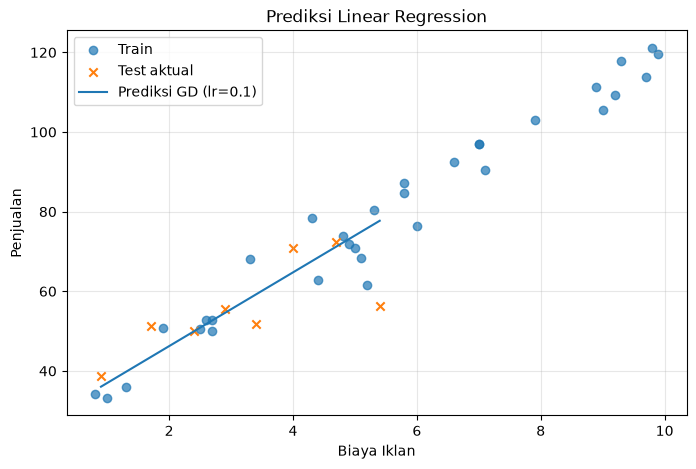

Learning rate terpilih dari loss train: 0.1
MSE test: 77.47740782082221
R2 test: 0.2822915902987583
Perubahan prediksi per satu unit BiayaIklan mendekati: 9.259671424951428 satuan Penjualan.
Perbandingan MSE test: normal equation = 77.47740782082218 ; gradient descent = 77.47740782082221


In [8]:
best_lr = min(gd_models, key=lambda lr: gd_models[lr][3][-1])
best_gd = gd_models[best_lr]
pred_test_gd = predict_linear_gd(X_test_ads, best_gd)

order = np.argsort(X_test_ads[:, 0])
plt.figure(figsize=(8, 5))
plt.scatter(X_train_ads[:, 0], y_train_ads, label="Train", alpha=0.7)
plt.scatter(X_test_ads[:, 0], y_test_ads, label="Test aktual", marker="x")
plt.plot(X_test_ads[order, 0], pred_test_gd[order], label=f"Prediksi GD (lr={best_lr})")
plt.xlabel("Biaya Iklan")
plt.ylabel("Penjualan")
plt.title("Prediksi Linear Regression")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

print("Learning rate terpilih dari loss train:", best_lr)
print("MSE test:", mse_manual(y_test_ads, pred_test_gd))
print("R2 test:", r2_manual(y_test_ads, pred_test_gd))
print("Perubahan prediksi per satu unit BiayaIklan mendekati:", float(best_gd[0][1] / best_gd[2][0]), "satuan Penjualan.")
print("Perbandingan MSE test: normal equation =", mse_manual(y_test_ads, pred_test_normal),
      "; gradient descent =", mse_manual(y_test_ads, pred_test_gd))


# B. Simple Logistic Regression

## B1. Memahami data dan distribusi kelas
`Spam` harus berupa label biner (0 dan 1). Fitur: `JumlahLink` dan `KataPromo`.


,Jumlah
Spam,
0.0,35
1.0,25


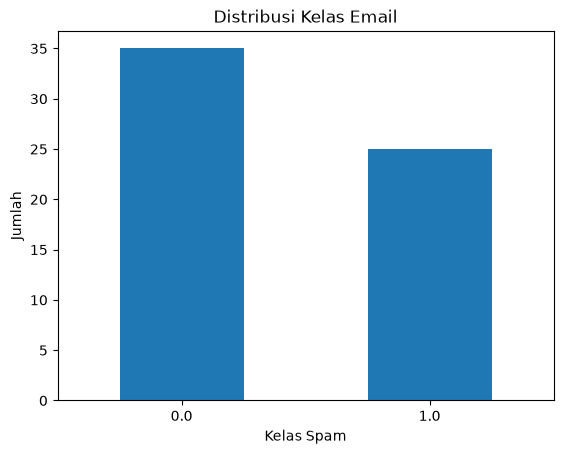

In [9]:
email = email_df.copy()
for col in ["JumlahLink", "KataPromo", "Spam"]:
    email[col] = pd.to_numeric(email[col], errors="raise")

X_email_all = email[["JumlahLink", "KataPromo"]].to_numpy(dtype=float)
y_email_all = email["Spam"].to_numpy(dtype=float)
classes = np.unique(y_email_all)
if not set(classes).issubset({0.0, 1.0}) or len(classes) != 2:
    raise ValueError(f"Kolom Spam harus berisi dua kelas 0 dan 1; ditemukan {classes}")

display(email["Spam"].value_counts().sort_index().rename("Jumlah").to_frame())
email["Spam"].value_counts().sort_index().plot(kind="bar", rot=0)
plt.xlabel("Kelas Spam")
plt.ylabel("Jumlah")
plt.title("Distribusi Kelas Email")
plt.show()


## B2. Membagi data train dan test
Menggunakan 75% data training dan 25% data testing.


In [10]:
X_train_email, X_test_email, y_train_email, y_test_email, train_idx_email, test_idx_email = train_test_split_manual(
    X_email_all, y_email_all, test_size=0.25, random_state=RANDOM_STATE, stratify=True, return_indices=True
)
print("Data train:", len(X_train_email))
print("Data test:", len(X_test_email))
print("Distribusi train:", pd.Series(y_train_email).value_counts().sort_index().to_dict())
print("Distribusi test:", pd.Series(y_test_email).value_counts().sort_index().to_dict())

assert not np.intersect1d(train_idx_email, test_idx_email).size
assert np.array_equal(X_train_email, X_email_all[train_idx_email])
assert np.array_equal(X_test_email, X_email_all[test_idx_email])

Data train: 44
Data test: 16
Distribusi train: {0.0: 26, 1.0: 18}
Distribusi test: {0.0: 9, 1.0: 7}


## B3. Implementasi Logistic Regression manual dengan Gradient Descent
Learning rate 0.1 dan 10000 iterasi. Fitur distandardisasi untuk stabilitas numerik.


Parameter [intercept, koefisien fitur terstandardisasi]: [-2.66747093  8.14600357  7.93124808]


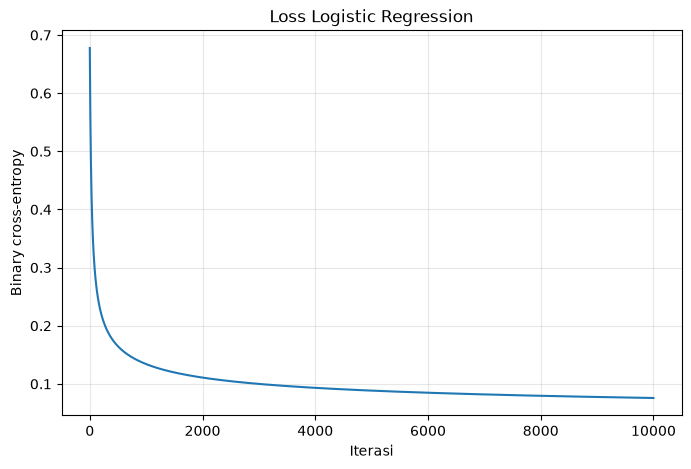

In [11]:
def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))

def fit_logistic_regression(X, y, learning_rate=0.1, iterations=10000):
    X = np.asarray(X, dtype=float)
    y = np.asarray(y, dtype=float).reshape(-1)
    mean_x = X.mean(axis=0)
    std_x = X.std(axis=0)
    std_x[std_x == 0] = 1
    X_scaled = (X - mean_x) / std_x
    X_bias = np.column_stack([np.ones(len(X_scaled)), X_scaled])
    theta = np.zeros(X_bias.shape[1], dtype=float)
    losses = []
    eps = 1e-12
    for _ in range(iterations):
        probs = sigmoid(X_bias @ theta)
        gradient = (X_bias.T @ (probs - y)) / len(y)
        theta -= learning_rate * gradient
        probs_after = np.clip(sigmoid(X_bias @ theta), eps, 1 - eps)
        loss = -np.mean(y * np.log(probs_after) + (1 - y) * np.log(1 - probs_after))
        losses.append(loss)
    return theta, mean_x, std_x, np.asarray(losses)

def predict_proba_logistic(X, fitted):
    theta, mean_x, std_x, _ = fitted
    X = np.asarray(X, dtype=float)
    X_scaled = (X - mean_x) / std_x
    X_bias = np.column_stack([np.ones(len(X_scaled)), X_scaled])
    return sigmoid(X_bias @ theta)

def predict_logistic(X, fitted, threshold=0.5):
    return (predict_proba_logistic(X, fitted) >= threshold).astype(int)

logistic_model = fit_logistic_regression(
    X_train_email, y_train_email, learning_rate=0.1, iterations=10000
)
print("Parameter [intercept, koefisien fitur terstandardisasi]:", logistic_model[0])
plt.figure(figsize=(8, 5))
plt.plot(logistic_model[3])
plt.xlabel("Iterasi")
plt.ylabel("Binary cross-entropy")
plt.title("Loss Logistic Regression")
plt.grid(True, alpha=0.3)
plt.show()


## B4. Evaluasi klasifikasi manual
Metrik: confusion matrix, accuracy, precision, recall, F1-score, dan log loss.


Confusion matrix di atas berurutan kelas 0 lalu 1, dengan baris sebagai label aktual dan kolom sebagai prediksi. TN adalah email bukan spam yang dikenali benar; FP adalah email bukan spam yang keliru ditandai spam; FN adalah spam yang terlewat dan diprediksi bukan spam; TP adalah spam yang dikenali benar.

In [12]:
def confusion_matrix_manual(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=int)
    y_pred = np.asarray(y_pred, dtype=int)
    return np.array([
        [np.sum((y_true == 0) & (y_pred == 0)), np.sum((y_true == 0) & (y_pred == 1))],
        [np.sum((y_true == 1) & (y_pred == 0)), np.sum((y_true == 1) & (y_pred == 1))],
    ])

def classification_metrics_manual(y_true, y_pred):
    cm = confusion_matrix_manual(y_true, y_pred)
    tn, fp, fn, tp = cm.ravel()
    accuracy = (tp + tn) / max(tp + tn + fp + fn, 1)
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    return cm, {
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-score": f1,
    }

pred_train_email = predict_logistic(X_train_email, logistic_model)
pred_test_email = predict_logistic(X_test_email, logistic_model)
cm_train, metrics_train = classification_metrics_manual(y_train_email, pred_train_email)
cm_test, metrics_test = classification_metrics_manual(y_test_email, pred_test_email)

print("Confusion matrix test (baris aktual, kolom prediksi):")
display(pd.DataFrame(cm_test, index=["Aktual 0", "Aktual 1"], columns=["Prediksi 0", "Prediksi 1"]))
display(pd.DataFrame({"Train": metrics_train, "Test": metrics_test}))

proba_test_email = np.clip(predict_proba_logistic(X_test_email, logistic_model), 1e-12, 1 - 1e-12)
log_loss_test = -np.mean(
    y_test_email * np.log(proba_test_email)
    + (1 - y_test_email) * np.log(1 - proba_test_email)
)
print("Log loss test:", float(log_loss_test))


Confusion matrix test (baris aktual, kolom prediksi):


,Prediksi 0,Prediksi 1
Aktual 0,9,0
Aktual 1,4,3


,Train,Test
Accuracy,0.977273,0.750000
Precision,0.947368,1.000000
Recall,1.000000,0.428571
F1-score,0.972973,0.600000


Log loss test: 1.541352187727402


## B5. Pengaruh threshold
Bandingkan threshold 0.3, 0.5, dan 0.7 untuk melihat perubahan precision dan recall.


In [13]:
threshold_rows = []
prob_test = predict_proba_logistic(X_test_email, logistic_model)
for threshold in [0.3, 0.5, 0.7]:
    pred = (prob_test >= threshold).astype(int)
    cm, metrics = classification_metrics_manual(y_test_email, pred)
    tn, fp, fn, tp = cm.ravel()
    threshold_rows.append({"Threshold": threshold, "TN": tn, "FP": fp, "FN": fn, "TP": tp, **metrics})
threshold_results = pd.DataFrame(threshold_rows)
display(threshold_results)
low = threshold_results.loc[threshold_results["Threshold"] == 0.3].iloc[0]
high = threshold_results.loc[threshold_results["Threshold"] == 0.7].iloc[0]
print(f"Pada test, threshold 0.3 menghasilkan FP={int(low['FP'])} dan FN={int(low['FN'])}; "
      f"threshold 0.7 menghasilkan FP={int(high['FP'])} dan FN={int(high['FN'])}.")


,Threshold,TN,FP,FN,TP,Accuracy,Precision,Recall,F1-score
0,0.3,9,0,3,4,0.8125,1.0,0.571429,0.727273
1,0.5,9,0,4,3,0.7500,1.0,0.428571,0.600000
2,0.7,9,0,4,3,0.7500,1.0,0.428571,0.600000


Pada test, threshold 0.3 menghasilkan FP=0 dan FN=3; threshold 0.7 menghasilkan FP=0 dan FN=4.


## B6. Visualisasi dan kesimpulan


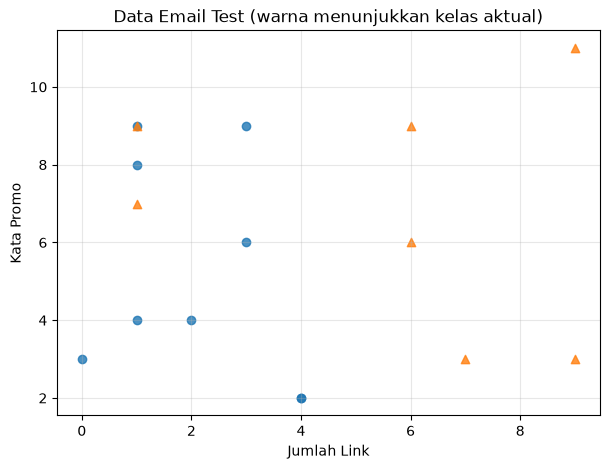

Accuracy test: 0.750
Precision test: 1.000
Recall test: 0.429
F1-score test: 0.600
Confusion matrix test memberi TN=9, FP=0, FN=4, TP=3. False positive adalah email bukan spam yang salah ditandai spam; false negative adalah spam yang terlewat. Precision tinggi tidak berarti semua spam ditemukan: recall menunjukkan proporsi spam yang berhasil ditemukan.
Pada hasil test ini masih ada 4 spam yang diprediksi sebagai bukan spam (false negative).


In [14]:
plt.figure(figsize=(7, 5))
for label, marker, name in [(0, "o", "Bukan spam (aktual)"), (1, "^", "Spam (aktual)")]:
    mask = y_test_email == label
    plt.scatter(X_test_email[mask, 0], X_test_email[mask, 1], marker=marker, label=name, alpha=0.8)
plt.xlabel("Jumlah Link")
plt.ylabel("Kata Promo")
plt.title("Data Email Test (warna menunjukkan kelas aktual)")
plt.grid(True, alpha=0.3)
plt.show()

print(f"Accuracy test: {metrics_test['Accuracy']:.3f}")
print(f"Precision test: {metrics_test['Precision']:.3f}")
print(f"Recall test: {metrics_test['Recall']:.3f}")
print(f"F1-score test: {metrics_test['F1-score']:.3f}")
print(f"Confusion matrix test memberi TN={cm_test[0,0]}, FP={cm_test[0,1]}, FN={cm_test[1,0]}, TP={cm_test[1,1]}. "
      "False positive adalah email bukan spam yang salah ditandai spam; false negative adalah spam yang terlewat. "
      "Precision tinggi tidak berarti semua spam ditemukan: recall menunjukkan proporsi spam yang berhasil ditemukan.")
if metrics_test["Recall"] < 1:
    print(f"Pada hasil test ini masih ada {cm_test[1,0]} spam yang diprediksi sebagai bukan spam (false negative).")


# C. Pertanyaan Konseptual

## C1. Apa perbedaan Linear Regression dan Logistic Regression?
Linear Regression memprediksi nilai numerik kontinu, sedangkan Logistic Regression memprediksi probabilitas kelas dan digunakan untuk klasifikasi.

## C2. Mengapa data dibagi menjadi training dan testing?
Training digunakan untuk mempelajari parameter model. Testing digunakan untuk mengukur kemampuan model pada data yang tidak digunakan saat pelatihan.

## C3. Apa fungsi learning rate pada Gradient Descent?
Learning rate menentukan besar langkah pembaruan parameter setiap iterasi. Terlalu kecil membuat proses lambat, sedangkan terlalu besar dapat menyebabkan optimisasi tidak stabil atau gagal konvergen.

## C4. Apa itu overfitting?
Overfitting terjadi ketika model terlalu menyesuaikan diri dengan data training sehingga performanya baik pada training tetapi buruk pada data baru.

## C5. Mengapa evaluasi model penting?
Evaluasi membantu mengukur kualitas prediksi, membandingkan model, dan memahami jenis kesalahan yang dibuat sebelum model digunakan.


# Scikit-learn
Bagian ini membandingkan model manual dengan model scikit-learn pada indeks training dan testing yang sama persis. Linear Regression seharusnya memberi prediksi hampir identik; Logistic Regression dapat berbeda karena scikit-learn menggunakan regularisasi L2 dan solver `lbfgs`.

In [15]:
try:
    from sklearn.linear_model import LinearRegression, LogisticRegression
    from sklearn.metrics import (
        accuracy_score,
        confusion_matrix,
        f1_score,
        mean_absolute_error,
        mean_squared_error,
        precision_score,
        r2_score,
        recall_score,
    )

    assert np.array_equal(X_train_ads[:, 0], X_ads_all[train_idx_ads])
    assert np.array_equal(X_test_ads[:, 0], X_ads_all[test_idx_ads])
    assert np.array_equal(X_train_email, X_email_all[train_idx_email])
    assert np.array_equal(X_test_email, X_email_all[test_idx_email])

    sk_linear = LinearRegression().fit(X_train_ads, y_train_ads)
    sk_linear_test = sk_linear.predict(X_test_ads)
    manual_linear_test = predict_linear(X_test_ads, theta_normal)
    assert np.allclose(manual_linear_test, sk_linear_test, rtol=1e-8, atol=1e-8)

    linear_parameter_comparison = pd.DataFrame({
        "Parameter": ["Intercept", "Koefisien BiayaIklan"],
        "Manual (persamaan normal)": [theta_normal[0], theta_normal[1]],
        "Scikit-learn": [sk_linear.intercept_, sk_linear.coef_[0]],
    })
    display(linear_parameter_comparison)

    linear_metrics_comparison = pd.DataFrame({
        "Metrik test": ["MAE", "MSE", "RMSE", "R²"],
        "Manual": [
            mae_manual(y_test_ads, manual_linear_test),
            mse_manual(y_test_ads, manual_linear_test),
            rmse_manual(y_test_ads, manual_linear_test),
            r2_manual(y_test_ads, manual_linear_test),
        ],
        "Scikit-learn": [
            mean_absolute_error(y_test_ads, sk_linear_test),
            mean_squared_error(y_test_ads, sk_linear_test),
            np.sqrt(mean_squared_error(y_test_ads, sk_linear_test)),
            r2_score(y_test_ads, sk_linear_test),
        ],
    })
    display(linear_metrics_comparison)
    print("Maksimum selisih prediksi regresi pada test:", float(np.max(np.abs(manual_linear_test - sk_linear_test))))

    # LogisticRegression menerima baris training/test yang sama dengan model manual.
    # Model scikit-learn memakai regularisasi L2 default (C=1.0) dan solver lbfgs.
    sk_logistic = LogisticRegression(solver="lbfgs", C=1.0, max_iter=10000, random_state=RANDOM_STATE)
    sk_logistic.fit(X_train_email, y_train_email.astype(int))
    sk_probability_test = sk_logistic.predict_proba(X_test_email)[:, 1]
    sk_prediction_test = (sk_probability_test >= 0.5).astype(int)
    manual_probability_test = predict_proba_logistic(X_test_email, logistic_model)
    manual_prediction_test = (manual_probability_test >= 0.5).astype(int)

    manual_cm, manual_classification = classification_metrics_manual(y_test_email, manual_prediction_test)
    sk_cm = confusion_matrix(y_test_email.astype(int), sk_prediction_test, labels=[0, 1])
    sk_classification = {
        "Accuracy": accuracy_score(y_test_email, sk_prediction_test),
        "Precision": precision_score(y_test_email, sk_prediction_test, zero_division=0),
        "Recall": recall_score(y_test_email, sk_prediction_test, zero_division=0),
        "F1-score": f1_score(y_test_email, sk_prediction_test, zero_division=0),
    }
    logistic_metrics_comparison = pd.DataFrame({
        "Metrik test (threshold=0.5)": ["Accuracy", "Precision", "Recall", "F1-score"],
        "Manual": [manual_classification[name] for name in ["Accuracy", "Precision", "Recall", "F1-score"]],
        "Scikit-learn": [sk_classification[name] for name in ["Accuracy", "Precision", "Recall", "F1-score"]],
    })
    display(logistic_metrics_comparison)
    confusion_comparison = pd.concat({
        "Manual": pd.DataFrame(manual_cm, index=["Aktual 0", "Aktual 1"], columns=["Prediksi 0", "Prediksi 1"]),
        "Scikit-learn": pd.DataFrame(sk_cm, index=["Aktual 0", "Aktual 1"], columns=["Prediksi 0", "Prediksi 1"]),
    }, axis=1)
    print("Confusion matrix: baris = kelas aktual (0 bukan spam, 1 spam); kolom = kelas prediksi.")
    display(confusion_comparison)
    print("Parameter Logistic Regression manual [intercept, koefisien terstandardisasi]:", logistic_model[0])
    print("Parameter Logistic Regression scikit-learn [intercept, koefisien pada fitur asli]:", sk_logistic.intercept_, sk_logistic.coef_[0])
    print("Scikit-learn memakai regularisasi L2 dan solver lbfgs; parameter dan hasil dapat berbeda dari optimisasi manual tanpa regularisasi.")
    print(f"Manual test: accuracy={manual_classification['Accuracy']:.3f}, precision={manual_classification['Precision']:.3f}, recall={manual_classification['Recall']:.3f}, F1={manual_classification['F1-score']:.3f}.")
    print(f"Scikit-learn test: accuracy={sk_classification['Accuracy']:.3f}, precision={sk_classification['Precision']:.3f}, recall={sk_classification['Recall']:.3f}, F1={sk_classification['F1-score']:.3f}.")
except ImportError:
    print("Scikit-learn belum terpasang. Bagian utama notebook tetap berjalan. Untuk bagian perbandingan, pasang dengan: python -m pip install scikit-learn")

,Parameter,Manual (persamaan normal),Scikit-learn
0,Intercept,27.709065,27.709065
1,Koefisien BiayaIklan,9.259671,9.259671


,Metrik test,Manual,Scikit-learn
0,MAE,5.979788,5.979788
1,MSE,77.477408,77.477408
2,RMSE,8.802125,8.802125
3,R²,0.282292,0.282292


Maksimum selisih prediksi regresi pada test: 2.842170943040401e-14


,Metrik test (threshold=0.5),Manual,Scikit-learn
0,Accuracy,0.750000,0.687500
1,Precision,1.000000,1.000000
2,Recall,0.428571,0.285714
3,F1-score,0.600000,0.444444


Confusion matrix: baris = kelas aktual (0 bukan spam, 1 spam); kolom = kelas prediksi.


Manual            Scikit-learn           
         Prediksi 0 Prediksi 1   Prediksi 0 Prediksi 1
Aktual 0          9          0            9          0
Aktual 1          4          3            5          2

Parameter Logistic Regression manual [intercept, koefisien terstandardisasi]: [-2.66747093  8.14600357  7.93124808]
Parameter Logistic Regression scikit-learn [intercept, koefisien pada fitur asli]: [-16.47968417] [1.38977515 1.29012778]
Scikit-learn memakai regularisasi L2 dan solver lbfgs; parameter dan hasil dapat berbeda dari optimisasi manual tanpa regularisasi.
Manual test: accuracy=0.750, precision=1.000, recall=0.429, F1=0.600.
Scikit-learn test: accuracy=0.688, precision=1.000, recall=0.286, F1=0.444.


## Selesai
Jalankan semua cell dari atas ke bawah (**Run → Run All**) dan simpan notebook setelah output muncul. Pastikan file CSV ikut dikumpulkan bersama notebook.
